In [13]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import xgboost as xgb
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm

# Configuración de gráficos estilo paper
plt.style.use('seaborn-v0_8-whitegrid')
tqdm.pandas() # Para ver barras de progreso en pandas

In [14]:
def prepare_train_matrices(train_peptides):
    """Agrupa los péptidos de train por longitud y los convierte a matrices numéricas."""
    train_arrays_by_len = {}
    
    # Agrupar por longitud
    df_train_peps = pd.DataFrame({'peptide': train_peptides.unique()})
    df_train_peps['len'] = df_train_peps['peptide'].apply(len)
    
    for L, group in df_train_peps.groupby('len'):
        # Convertir strings a arrays de bytes (ASCII) para cálculo matricial rápido
        byte_arrays = [np.frombuffer(p.encode(), dtype=np.uint8) for p in group['peptide']]
        train_arrays_by_len[L] = np.vstack(byte_arrays)
        
    return train_arrays_by_len

def get_min_hamming_distance(test_pep, train_arrays_by_len):
    """Calcula la distancia mínima de Hamming contra todo el train set en milisegundos."""
    L = len(test_pep)
    if L not in train_arrays_by_len:
        return 99 # Si no hay péptidos de esta longitud en train, es 100% novedoso
        
    # Convertir péptido test a bytes
    test_arr = np.frombuffer(test_pep.encode(), dtype=np.uint8)
    train_mat = train_arrays_by_len[L]
    
    # Broadcast compare: compara el test contra TODOS los del train a la vez
    dists = np.sum(train_mat != test_arr, axis=1)
    
    return int(dists.min())

In [15]:
PEPTIDE_COL = 'Peptide' # <--- CAMBIA ESTO AL NOMBRE REAL DE TU COLUMNA SI ES DISTINTO

# 1. Definir rutas (Asegúrate de que coinciden con tu estructura)
data_path = Path('../data/processed/dataset_80_20_normalized_tcr_with_cohort_and_rank.csv')
models_dir = Path('../models/production/hybrid_ensemble')

# 2. Cargar el dataset completo
print("Cargando datos...")
df = pd.read_csv(data_path)

# 3. Separar features y label igual que en tu script original
features_to_drop = ['immunogenicity', 'mut_is_binding_pos', 'bestWTMatchType_I', 
                    'DAI_MixMHC_mbp', 'mutant_rank']
X_df = df.select_dtypes(include=['float64', 'int64']).drop(columns=features_to_drop, errors='ignore')

X = X_df.values
y = df['immunogenicity'].values

# 4. REPLICAR EL SPLIT EXACTO (random_state=42 es clave)
X_dev, X_test, y_dev, y_test, df_dev, df_test = train_test_split(
    X, y, df, test_size=0.20, random_state=42, stratify=y
)

print(f"Train/Dev shape: {df_dev.shape}")
print(f"Test shape: {df_test.shape}")

Cargando datos...
Train/Dev shape: (10092, 32)
Test shape: (2524, 32)


In [16]:
print("1. Preparando matrices del Train set...")
# Extraemos los péptidos únicos del train para no repetir cálculos
train_peptides = df_dev[PEPTIDE_COL].dropna()
train_matrices = prepare_train_matrices(train_peptides)

print("2. Calculando distancia mínima para cada péptido en el Test set...")
# Aplicamos la función a cada fila del Test
df_test['min_hamming_to_train'] = df_test[PEPTIDE_COL].progress_apply(
    lambda p: get_min_hamming_distance(str(p), train_matrices)
)

# 3. Clasificamos en "Novedoso" vs "Fuga (Leakage)"
df_test['is_novel'] = df_test['min_hamming_to_train'] > 1

# Resumen de la fuga
fuga_pct = (~df_test['is_novel']).mean() * 100
print(f"\n--- RESULTADOS DE LA AUDITORÍA ---")
print(f"Péptidos con Fuga de Homología (Hamming <= 1): {fuga_pct:.2f}%")
print(f"Péptidos 100% Novedosos (Hamming >= 2): {100 - fuga_pct:.2f}%")

1. Preparando matrices del Train set...
2. Calculando distancia mínima para cada péptido en el Test set...


  0%|          | 0/2524 [00:00<?, ?it/s]


--- RESULTADOS DE LA AUDITORÍA ---
Péptidos con Fuga de Homología (Hamming <= 1): 24.48%
Péptidos 100% Novedosos (Hamming >= 2): 75.52%


In [17]:
# Definición de la arquitectura (necesaria para cargar los pesos)
class ImprovedMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, dropout_rate=0.3):
        super(ImprovedMLP, self).__init__()
        layers = []
        prev_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(prev_dim, hidden_dim), nn.BatchNorm1d(hidden_dim),
                nn.LeakyReLU(0.1), nn.Dropout(dropout_rate)
            ])
            prev_dim = hidden_dim
        layers.append(nn.Linear(prev_dim, 1))
        self.network = nn.Sequential(*layers)
    def forward(self, x):
        return self.network(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Cargar Scaler y transformar Test
scaler = joblib.load(models_dir / 'scaler.pkl')
X_test_scaled = scaler.transform(X_test)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)

# 2. Cargar PyTorch (IMPORTANTE: Pon las dimensiones ocultas correctas de tu último Optuna)
# Asumo unas dimensiones por defecto, cámbialas si Optuna sacó otras.
input_dim = X_test.shape[1]
# Basado en el log de error, esta es la arquitectura exacta que guardaste:
pytorch_model = ImprovedMLP(input_dim, hidden_dims=[180, 77, 251], dropout_rate=0.3).to(device)
pytorch_model.load_state_dict(torch.load(models_dir / 'pytorch_final.pth', map_location=device, weights_only=True))
pytorch_model.eval()

# 3. Cargar XGBoost
xgb_model = xgb.XGBClassifier()
xgb_model.load_model(models_dir / 'xgboost_final.json')

# 4. Generar Predicciones
with torch.no_grad():
    p_prob = torch.sigmoid(pytorch_model(X_test_tensor)).cpu().numpy().flatten()
x_prob = xgb_model.predict_proba(X_test_scaled)[:, 1]

# Asumiendo pesos 50/50 (Cámbialos si tu ensemble sacó otros pesos, ej: 0.6 y 0.4)
w1, w2 = 0.5, 0.5 
df_test['ensemble_prob'] = (w1 * p_prob) + (w2 * x_prob)
df_test['true_label'] = y_test

print("Predicciones cargadas y calculadas en el Test Set.")

Predicciones cargadas y calculadas en el Test Set.


AUC Global: 0.891 (n=2524)
AUC Novedosos: 0.804 (n=1906)
AUC Fuga: 0.987 (n=618)


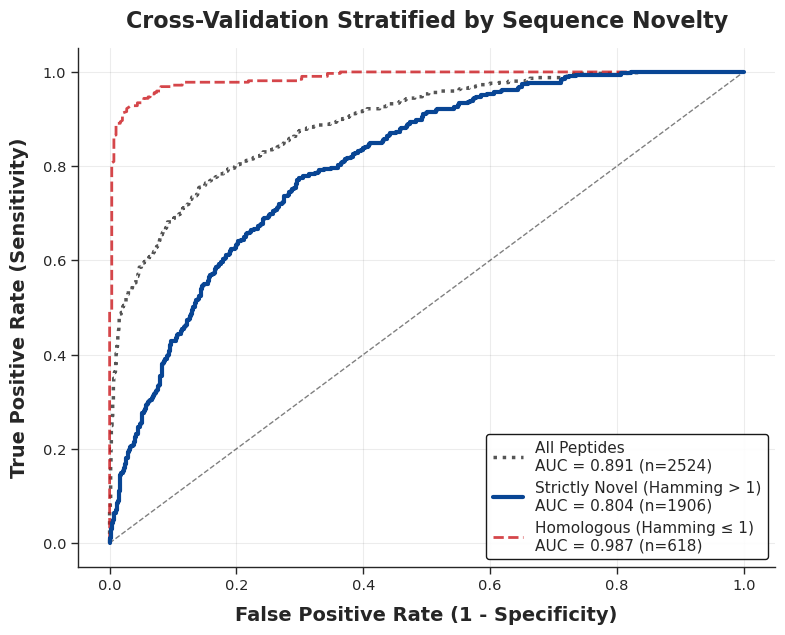

✓ Figura guardada exitosamente en: Figure_Homology_Leakage_ROC_Paper.png


In [19]:
# 1. Separar los dos grupos y contar las N (Muestras)
novel_mask = df_test['is_novel'] == True
leaked_mask = df_test['is_novel'] == False

y_true_novel, y_prob_novel = df_test.loc[novel_mask, 'true_label'], df_test.loc[novel_mask, 'ensemble_prob']
y_true_leak, y_prob_leak = df_test.loc[leaked_mask, 'true_label'], df_test.loc[leaked_mask, 'ensemble_prob']
y_true_all, y_prob_all = df_test['true_label'], df_test['ensemble_prob']

n_novel = novel_mask.sum()
n_leak = leaked_mask.sum()
n_all = len(df_test)

# 2. Calcular AUCs
auc_novel = roc_auc_score(y_true_novel, y_prob_novel)
auc_leak = roc_auc_score(y_true_leak, y_prob_leak) if n_leak > 0 else 0
auc_all = roc_auc_score(y_true_all, y_prob_all)

print(f"AUC Global: {auc_all:.3f} (n={n_all})")
print(f"AUC Novedosos: {auc_novel:.3f} (n={n_novel})")
if n_leak > 0:
    print(f"AUC Fuga: {auc_leak:.3f} (n={n_leak})")

# ==============================================================================
# 3. DIBUJO DE LA CURVA ROC (CALIDAD PAPER)
# ==============================================================================
# Forzamos un estilo blanco y limpio por si tenías arrastrado un dark mode
plt.style.use('default')
sns.set_theme(style="ticks", context="paper", font_scale=1.2)

fig, ax = plt.subplots(figsize=(8, 6.5))

# Línea 1: Todos los péptidos (Gris oscuro, punteada gruesa)
fpr_all, tpr_all, _ = roc_curve(y_true_all, y_prob_all)
ax.plot(fpr_all, tpr_all, color='#555555', linestyle=':', linewidth=2.5, zorder=2,
        label=f'All Peptides\nAUC = {auc_all:.3f} (n={n_all})')

# Línea 2: Péptidos Novedosos - EL RESULTADO ESTRELLA (Azul corporativo/científico, sólida)
fpr_nov, tpr_nov, _ = roc_curve(y_true_novel, y_prob_novel)
ax.plot(fpr_nov, tpr_nov, color='#084594', linestyle='-', linewidth=3, zorder=4,
        label=f'Strictly Novel (Hamming > 1)\nAUC = {auc_novel:.3f} (n={n_novel})')

# Línea 3: Péptidos Fuga (Rojo apagado, discontinua)
if n_leak > 0:
    fpr_leak, tpr_leak, _ = roc_curve(y_true_leak, y_prob_leak)
    ax.plot(fpr_leak, tpr_leak, color='#cb181d', linestyle='--', linewidth=2, alpha=0.8, zorder=3,
            label=f'Homologous (Hamming ≤ 1)\nAUC = {auc_leak:.3f} (n={n_leak})')

# Línea base aleatoria (Diagonal)
ax.plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=1, alpha=0.5, zorder=1)

# Estética de los ejes y textos
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=14, fontweight='bold', labelpad=10)
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=14, fontweight='bold', labelpad=10)
ax.set_title('Cross-Validation Stratified by Sequence Novelty', fontsize=16, fontweight='bold', pad=15)

# Cuadrícula muy sutil para no ensuciar
ax.grid(True, linestyle='-', alpha=0.15, color='gray')

# Leyenda profesional (con un poco de opacidad por si pisa la curva)
legend = ax.legend(loc='lower right', fontsize=11, frameon=True, edgecolor='black', framealpha=0.9)
legend.get_frame().set_linewidth(1.0)

# Eliminar el borde superior y derecho (Despine)
sns.despine()

plt.tight_layout()

# Guardar en alta resolución (300 dpi es el estándar para papers)
save_path = '../results/figures/Post_HOC_analysis/Figure_Homology_Leakage_ROC_Paper.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Figura guardada exitosamente en: {save_path}")